In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations

In [5]:
def W_true(z):
    return -5.0 * np.maximum(1.0 - np.abs(z), 0.0)

def W_true_prime(z):
    out = np.zeros_like(z)
    out[(z > 0.0) & (z < 1.0)] = 5.0
    out[(z < 0.0) & (z > -1.0)] = -5.0
    return out

# Grid and convolution
def make_offsets(Nx, dx):
    return np.arange(-(Nx - 1), Nx) * dx

def conv_valid(rho_snapshot, kernel_values, dx):
    return dx * np.convolve(rho_snapshot, kernel_values, mode="valid")

# Forward difference
def Dx_plus(v, dx):
    out = np.empty_like(v)
    out[:-1] = (v[1:] - v[:-1]) / dx
    out[-1] = -v[-1] / dx
    return out

# Local radial piecewise basis
def build_local_piecewise_basis(offsets, n_intervals=12, Lbox=6.0, degree=0):
    z = offsets.copy()
    r = np.abs(z)
    sgn = np.sign(z)
    edges = np.linspace(0.0, Lbox, n_intervals + 1)
    Psi = []
    dPsi = []
    params = []
    for j in range(n_intervals):
        a = edges[j]
        b = edges[j + 1]
        if j < n_intervals - 1:
            chi = ((r >= a) & (r < b)).astype(float)
        else:
            chi = ((r >= a) & (r <= b)).astype(float)
        for p in range(degree + 1):
            phi = (r ** p) * chi
            dPsi_jp = phi * sgn
            Phi = np.zeros_like(r)
            mid = (r >= a) & (r <= b)
            Phi[mid] = (r[mid] ** (p + 1) - a ** (p + 1)) / (p + 1)
            right = r > b
            Phi[right] = (b ** (p + 1) - a ** (p + 1)) / (p + 1)
            Psi.append(Phi)
            dPsi.append(dPsi_jp)
            params.append((j, p, a, b))

    return {
        "name": "local_piecewise",
        "params": np.array(params, dtype=object),
        "Psi": np.array(Psi),
        "dPsi": np.array(dPsi),
        "Lbox": Lbox,
    }


# Local radial Fourier basis
def build_local_fourier_basis(
    offsets,
    n_intervals=12,
    num_modes=2,
    Lbox=6.0,
):
    z = offsets.copy()
    r = np.abs(z)
    sgn = np.sign(z)
    edges = np.linspace(0.0, Lbox, n_intervals + 1)
    Psi = []
    dPsi = []
    params = []
    for j in range(n_intervals):
        a = edges[j]
        b = edges[j + 1]
        ell = b - a
        if j < n_intervals - 1:
            chi = ((r >= a) & (r < b)).astype(float)
        else:
            chi = ((r >= a) & (r <= b)).astype(float)
        s = (r - a) / ell
        phi_const = chi
        dPsi_const = phi_const * sgn
        Phi_const = np.zeros_like(r)
        mid = (r >= a) & (r <= b)
        Phi_const[mid] = r[mid] - a
        right = r > b
        Phi_const[right] = b - a
        Psi.append(Phi_const)
        dPsi.append(dPsi_const)
        params.append((j, "const", 0, a, b))
        for k in range(1, num_modes + 1):
            phi_cos = np.cos(2.0 * np.pi * k * s) * chi
            dPsi_cos = phi_cos * sgn
            Phi_cos = np.zeros_like(r)
            mid = (r >= a) & (r <= b)
            Phi_cos[mid] = (
                ell / (2.0 * np.pi * k)
                * np.sin(2.0 * np.pi * k * (r[mid] - a) / ell)
            )
            right = r > b
            Phi_cos[right] = 0.0
            Psi.append(Phi_cos)
            dPsi.append(dPsi_cos)
            params.append((j, "cos", k, a, b))
            phi_sin = np.sin(2.0 * np.pi * k * s) * chi
            dPsi_sin = phi_sin * sgn
            Phi_sin = np.zeros_like(r)
            mid = (r >= a) & (r <= b)
            Phi_sin[mid] = (
                ell / (2.0 * np.pi * k)
                * (1.0 - np.cos(2.0 * np.pi * k * (r[mid] - a) / ell))
            )
            right = r > b
            Phi_sin[right] = ell / (np.pi * k)
            Psi.append(Phi_sin)
            dPsi.append(dPsi_sin)
            params.append((j, "sin", k, a, b))

    return {
        "name": "local_fourier",
        "params": np.array(params, dtype=object),
        "Psi": np.array(Psi),
        "dPsi": np.array(dPsi),
        "Lbox": Lbox,
    }


# Local radial Gaussian basis
def build_local_gaussian_basis(
    offsets,
    n_intervals=12,
    num_centers_per_interval=2,
    sigma_factor=1.0,
    Lbox=6.0,
):
    z = offsets.copy()
    r = np.abs(z)
    sgn = np.sign(z)
    edges = np.linspace(0.0, Lbox, n_intervals + 1)
    Psi = []
    dPsi = []
    params = []
    r_unique = np.unique(r)
    r_unique.sort()
    for j in range(n_intervals):
        a = edges[j]
        b = edges[j + 1]
        ell = b - a
        centers = np.linspace(
            a + ell / (num_centers_per_interval + 1),
            b - ell / (num_centers_per_interval + 1),
            num_centers_per_interval,
        )
        sigma = sigma_factor * ell / num_centers_per_interval
        for c0 in centers:
            chi = ((r >= a) & (r <= b)).astype(float)
            phi = np.exp(-0.5 * ((r - c0) / sigma) ** 2) * chi
            dPsi_j = phi * sgn
            phi_unique = np.exp(-0.5 * ((r_unique - c0) / sigma) ** 2)
            phi_unique *= ((r_unique >= a) & (r_unique <= b)).astype(float)
            Phi_unique = np.zeros_like(r_unique)
            dr = np.diff(r_unique)
            Phi_unique[1:] = np.cumsum(
                0.5 * (phi_unique[1:] + phi_unique[:-1]) * dr
            )
            Phi = np.interp(r, r_unique, Phi_unique)
            Psi.append(Phi)
            dPsi.append(dPsi_j)
            params.append((j, c0, sigma, a, b))
    return {
        "name": "local_gaussian",
        "params": np.array(params, dtype=object),
        "Psi": np.array(Psi),
        "dPsi": np.array(dPsi),
        "Lbox": Lbox,
    }

# Build discrete A and b
def build_A_b_variational(rho, x, t, Psi, dPsi, m, kappa):
    dx = x[1] - x[0]
    dt = t[1] - t[0]
    T = t[-1] - t[0]
    Nt, Nx = rho.shape
    n_basis = Psi.shape[0]
    A = np.zeros((n_basis, n_basis))
    b = np.zeros(n_basis)
    for ell in range(Nt - 1):
        rho_l = rho[ell]
        rho_next = rho[ell + 1]
        rho_t = (rho_next - rho_l) / dt
        Hprime = kappa * np.maximum(rho_l, 0.0) ** (m - 1)
        Hprime_x = Dx_plus(Hprime, dx)
        F = rho_l * Hprime_x
        Psi_conv = np.zeros((n_basis, Nx))
        dPsi_conv = np.zeros((n_basis, Nx))
        for i in range(n_basis):
            Psi_conv[i] = conv_valid(rho_l, Psi[i], dx)
            dPsi_conv[i] = conv_valid(rho_l, dPsi[i], dx)
        for i in range(n_basis):
            b[i] += -dt * dx * np.sum(
                rho_t * Psi_conv[i]
                + dPsi_conv[i] * F
            )
            for j in range(n_basis):
                A[i, j] += dt * dx * np.sum(
                    rho_l * dPsi_conv[i] * dPsi_conv[j]
                )
    A /= T
    b /= T
    A = 0.5 * (A + A.T)
    return A, b

# PartInv
def partinv(A, b, K=2, max_iter=100, tol=1e-12):
    n = A.shape[1]
    c_tilde = A.T @ b
    I = np.argsort(np.abs(c_tilde))[-K:]
    support_history = []
    for _ in range(max_iter):
        I = np.array(sorted(I))
        support_history.append(tuple(I.tolist()))
        A_I = A[:, I]
        c_I = np.linalg.pinv(A_I) @ b
        r = b - A_I @ c_I
        c_tilde = np.zeros(n)
        c_tilde[I] = c_I
        J = np.setdiff1d(np.arange(n), I)
        if len(J) > 0:
            c_tilde[J] = A[:, J].T @ r
        I_new = np.argsort(np.abs(c_tilde))[-K:]
        if set(I_new.tolist()) == set(I.tolist()):
            I = np.array(sorted(I_new))
            break
        if np.linalg.norm(r) < tol:
            I = np.array(sorted(I_new))
            break
        I = I_new
    I = np.array(sorted(I))
    c = np.zeros(n)
    c[I] = np.linalg.pinv(A[:, I]) @ b
    support_history = list(dict.fromkeys(support_history))
    return c, I, support_history

# Restricted LS / RE pruning
def restricted_least_squares(A, b, support):
    support = np.array(sorted(support))
    c = np.zeros(A.shape[1])
    c[support] = np.linalg.pinv(A[:, support]) @ b
    RE = c.T @ A @ c - 2.0 * c.T @ b
    residual = np.linalg.norm(A @ c - b)
    return c, RE, residual

def re_pruning(A, b, candidate_support, sparsity):
    candidate_support = sorted(set(candidate_support))
    records = []
    for J in combinations(candidate_support, sparsity):
        cJ, RE, residual = restricted_least_squares(A, b, J)
        records.append({
            "support": tuple(J),
            "coef": cJ,
            "RE": RE,
            "residual": residual,
        })
    records = sorted(records, key=lambda r: r["RE"])
    return records

# Reconstruction and errors
def reconstruct_from_basis(c, Psi_plot, dPsi_plot):
    W_hat = np.zeros_like(Psi_plot[0])
    Wp_hat = np.zeros_like(dPsi_plot[0])
    for ci, Pi, dPi in zip(c, Psi_plot, dPsi_plot):
        W_hat += ci * Pi
        Wp_hat += ci * dPi
    return W_hat, Wp_hat

def rel_L2_mask(f_hat, f_ref, mask):
    denom = np.linalg.norm(f_ref[mask])
    if denom == 0.0:
        return np.nan
    return np.linalg.norm(f_hat[mask] - f_ref[mask]) / denom


# Run one basis

def run_one_basis(
    basis,
    rho,
    x,
    t,
    m,
    kappa,
    K_partinv=4,
    sparsity=2,
    plot_interval=(-6.0, 6.0),
    output_root="figures_sparse",
    tag="example1",
    exhaustive_piecewise=True,
):
    name = basis["name"]
    params = basis["params"]
    Psi = basis["Psi"]
    dPsi = basis["dPsi"]
    outdir = output_root
    os.makedirs(outdir, exist_ok=True)
    A, b = build_A_b_variational(
        rho=rho,
        x=x,
        t=t,
        Psi=Psi,
        dPsi=dPsi,
        m=m,
        kappa=kappa,
    )
    print("\n" + "=" * 72)
    print(f"Basis: {name}")
    print("=" * 72)
    print("A shape:", A.shape)
    print("cond(A):", np.linalg.cond(A))
    D = np.sqrt(np.maximum(np.diag(A), 1e-30))
    corr = A / np.outer(D, D)
    coherence = np.max(np.abs(corr - np.eye(len(params))))
    print("coherence:", coherence)
    c_part, supp_part, supp_hist = partinv(A, b, K=K_partinv, max_iter=100)
    if name == "local_piecewise" and exhaustive_piecewise:
        candidate_support = list(range(A.shape[1]))
    else:
        if len(supp_hist) == 0:
            candidate_support = supp_part.tolist()
        else:
            candidate_support = sorted(set(np.concatenate([np.array(s) for s in supp_hist])))
        if len(candidate_support) < sparsity:
            candidate_support = supp_part.tolist()
    records = re_pruning(A, b, candidate_support=candidate_support, sparsity=sparsity,)
    best = records[0]
    c_best = best["coef"]
    support_best = best["support"]
    print("\nPartInv final support:", supp_part)
    print("Candidate support:", candidate_support)
    print("\nBest RE support:", support_best)
    print("Best RE:", best["RE"])
    print("Residual:", best["residual"])
    print("\nRecovered active terms:")
    for idx in support_best:
        print(f"index={idx}, param={params[idx]}, coef={c_best[idx]:+.12e}")
    dx = x[1] - x[0]
    offsets = make_offsets(len(x), dx)
    mask = (offsets >= plot_interval[0]) & (offsets <= plot_interval[1])
    z_plot = offsets[mask]
    Psi_plot = Psi[:, mask]
    dPsi_plot = dPsi[:, mask]
    W_hat_raw, Wp_hat = reconstruct_from_basis(c_best, Psi_plot, dPsi_plot)
    W_ref = W_true(z_plot)
    Wp_ref = W_true_prime(z_plot)
    interval_errors = {}
    for R in [2, 4, 6]:
        mask_R = np.abs(z_plot) <= R
        W_hat_R = W_hat_raw + np.mean(W_ref[mask_R] - W_hat_raw[mask_R])
        err_W = rel_L2_mask(W_hat_R, W_ref, mask_R)
        err_Wp = rel_L2_mask(Wp_hat, Wp_ref, mask_R)
        interval_errors[R] = {
            "W": err_W,
            "Wp": err_Wp,
        }
    print("\nRelative L2 errors of W")
    for R in [2, 4, 6]:
        print(f"[-{R},{R}] : {interval_errors[R]['W']:.6e}")
    print("\nRelative L2 errors of W'")
    for R in [2, 4, 6]:
        print(f"[-{R},{R}] : {interval_errors[R]['Wp']:.6e}")
    W_hat = W_hat_raw + np.mean(W_ref - W_hat_raw)
    W_err = interval_errors[6]["W"]
    Wp_err = interval_errors[6]["Wp"]
    prefix = f"{tag}_{name}"

    plt.figure(figsize=(6.5, 4.5))
    plt.plot(z_plot, W_ref, "k-", lw=2.0, label="True W")
    plt.plot(z_plot, W_hat, "r--", lw=2.0, label="Learned W")
    plt.xlabel("z")
    plt.ylabel(r"$W(z)$")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{outdir}/{prefix}_sparse_W.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{outdir}/{prefix}_sparse_W.pdf", bbox_inches="tight")
    plt.show()

    plt.figure(figsize=(6.5, 4.5))
    plt.plot(z_plot, Wp_ref, "k-", lw=2.0, label="True W'")
    plt.plot(z_plot, Wp_hat, "r--", lw=2.0, label="Learned W'")
    plt.xlabel("z")
    plt.ylabel(r"$W'(z)$")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{outdir}/{prefix}_sparse_W_prime.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{outdir}/{prefix}_sparse_W_prime.pdf", bbox_inches="tight",)
    plt.show()

    np.savez(
        f"{outdir}/{prefix}_sparse_result.npz",
        basis_name=name,
        params=params,
        A=A,
        b=b,
        c_best=c_best,
        support_best=np.array(support_best),
        c_partinv=c_part,
        support_partinv=supp_part,
        z_plot=z_plot,
        W_hat=W_hat,
        Wp_hat=Wp_hat,
        W_true=W_ref,
        Wp_true=Wp_ref,
        W_error=W_err,
        Wp_error=Wp_err,
        W_error_2=interval_errors[2]["W"],
        Wp_error_2=interval_errors[2]["Wp"],
        W_error_4=interval_errors[4]["W"],
        Wp_error_4=interval_errors[4]["Wp"],
        W_error_6=interval_errors[6]["W"],
        Wp_error_6=interval_errors[6]["Wp"],
        RE=best["RE"],
        residual=best["residual"],
    )

    return {
        "basis": name,
        "params": params,
        "coef": c_best,
        "support": support_best,
        "W_error_2": interval_errors[2]["W"],
        "Wp_error_2": interval_errors[2]["Wp"],
        "W_error_4": interval_errors[4]["W"],
        "Wp_error_4": interval_errors[4]["Wp"],
        "W_error_6": interval_errors[6]["W"],
        "Wp_error_6": interval_errors[6]["Wp"],
        "RE": best["RE"],
        "residual": best["residual"],
    }

Loaded: example1_Cx6_Ct50.npz
tag: example1_Cx6_Ct50
rho shape: (201, 200)
x range: -5.995 5.944999999999999
dx: 0.05999999999999961
t range: 0.0 0.5
dt: 0.0025
m: 2
kappa: 0.2
offset range: -11.939999999999923 11.939999999999923

Basis: local_piecewise
A shape: (12, 12)
cond(A): inf
coherence: 1.0

PartInv final support: [2 3 4 5]
Candidate support: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

Best RE support: (0, 1)
Best RE: -0.8114360165144747
Residual: 0.005865140720605686

Recovered active terms:
index=0, param=[0 0 0.0 0.5], coef=+4.954238827228e+00
index=1, param=[1 0 0.5 1.0], coef=+5.628697571101e+00

Relative L2 errors of W
[-2,2] : 6.566352e-02
[-4,4] : 7.665778e-02
[-6,6] : 8.008616e-02

Relative L2 errors of W'
[-2,2] : 8.914648e-02
[-4,4] : 8.914648e-02
[-6,6] : 8.914648e-02


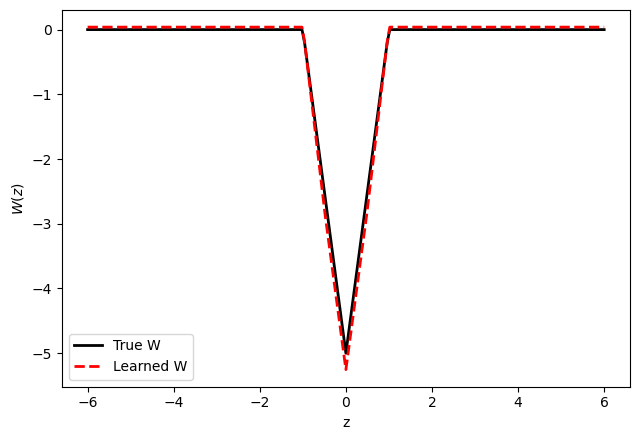

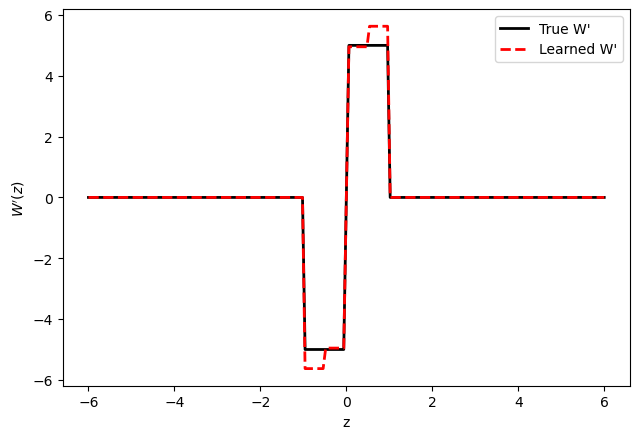


Basis: local_fourier
A shape: (60, 60)
cond(A): inf
coherence: 1.0

PartInv final support: [ 0  2  5 10 15 20 25 30]
Candidate support: [0, 2, 5, 10, 15, 20, 25, 30]

Best RE support: (0, 2, 5, 25)
Best RE: -2.729939958492956
Residual: 0.04865959575716554

Recovered active terms:
index=0, param=[0 'const' 0 0.0 0.5], coef=+8.446668748869e+00
index=2, param=[0 'sin' 1 0.0 0.5], coef=+3.698634438156e+01
index=5, param=[1 'const' 0 0.5 1.0], coef=+1.133935046073e+01
index=25, param=[5 'const' 0 2.5 3.0], coef=-2.112734482543e+00

Relative L2 errors of W
[-2,2] : 1.534945e+00
[-4,4] : 1.635488e+00
[-6,6] : 1.641883e+00

Relative L2 errors of W'
[-2,2] : 3.900211e+00
[-4,4] : 3.913065e+00
[-6,6] : 3.913065e+00


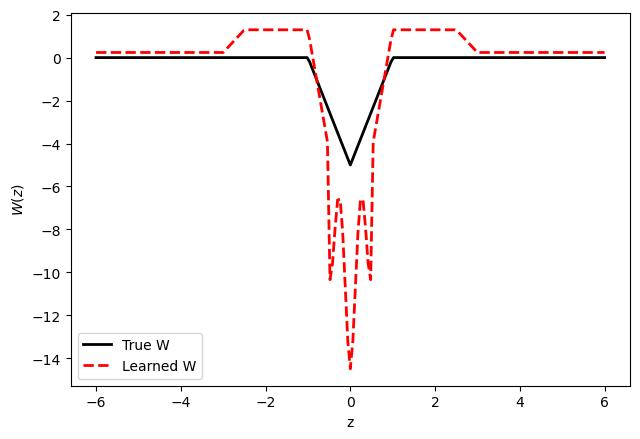

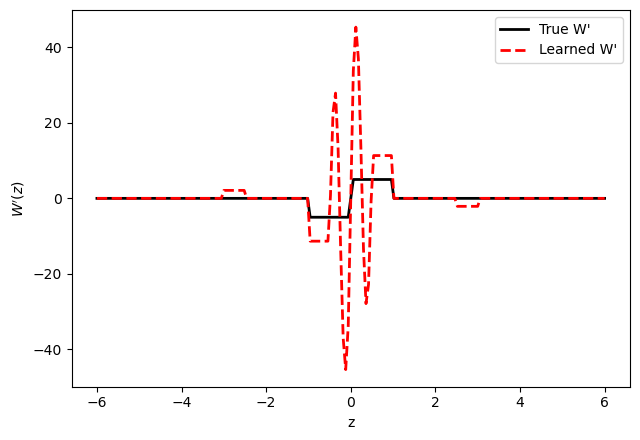


Basis: local_gaussian
A shape: (24, 24)
cond(A): inf
coherence: 1.0

PartInv final support: [ 2  5  6  7  8  9 10 11]
Candidate support: [2, 5, 6, 7, 8, 9, 10, 11]

Best RE support: (2, 5, 7, 9)
Best RE: -0.6457098409703933
Residual: 0.020426926472593997

Recovered active terms:
index=2, param=[1 0.6666666666666666 0.25 0.5 1.0], coef=+8.144365159369e+00
index=5, param=[2 1.3333333333333333 0.25 1.0 1.5], coef=+2.066436705456e+00
index=7, param=[3 1.8333333333333333 0.25 1.5 2.0], coef=-5.741816684019e+00
index=9, param=[4 2.3333333333333335 0.25 2.0 2.5], coef=+4.787612885080e+00

Relative L2 errors of W
[-2,2] : 3.118777e-01
[-4,4] : 4.063660e-01
[-6,6] : 4.241837e-01

Relative L2 errors of W'
[-2,2] : 1.073835e+00
[-4,4] : 1.217938e+00
[-6,6] : 1.217938e+00


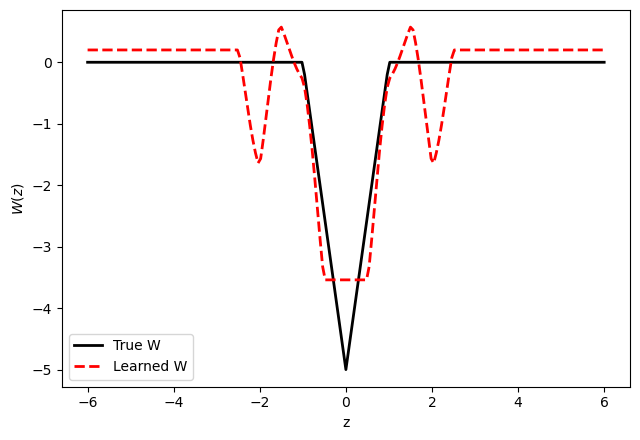

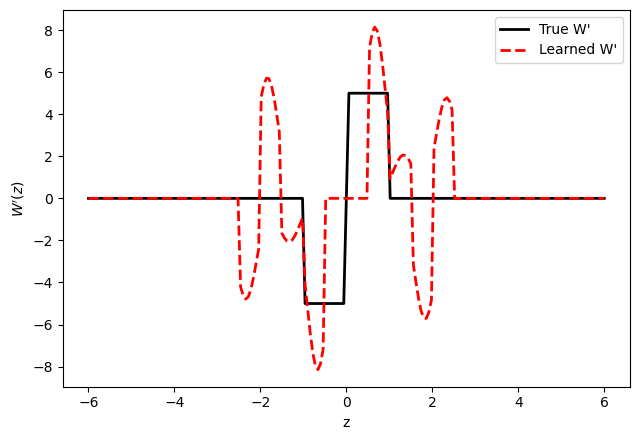



Summary
local_piecewise    W[-2,2]=6.5664e-02, W[-4,4]=7.6658e-02, W[-6,6]=8.0086e-02, W'[-2,2]=8.9146e-02, W'[-4,4]=8.9146e-02, W'[-6,6]=8.9146e-02, support=(0, 1)
local_fourier      W[-2,2]=1.5349e+00, W[-4,4]=1.6355e+00, W[-6,6]=1.6419e+00, W'[-2,2]=3.9002e+00, W'[-4,4]=3.9131e+00, W'[-6,6]=3.9131e+00, support=(0, 2, 5, 25)
local_gaussian     W[-2,2]=3.1188e-01, W[-4,4]=4.0637e-01, W[-6,6]=4.2418e-01, W'[-2,2]=1.0738e+00, W'[-4,4]=1.2179e+00, W'[-6,6]=1.2179e+00, support=(2, 5, 7, 9)


In [6]:

data_file = "example1_Cx6_Ct50.npz"
tag = os.path.splitext(os.path.basename(data_file))[0]
data = np.load(data_file)
x = data["x_obs"]
t = data["obs_times"]
rho = data["obs_snapshots"]
m = int(data["m"])
kappa = float(data["kappa"])
dx = x[1] - x[0]
Nx = len(x)
offsets = make_offsets(Nx, dx)

print("Loaded:", data_file)
print("tag:", tag)
print("rho shape:", rho.shape)
print("x range:", x.min(), x.max())
print("dx:", dx)
print("t range:", t[0], t[-1])
print("dt:", t[1] - t[0])
print("m:", m)
print("kappa:", kappa)
print("offset range:", offsets.min(), offsets.max())

# Build three local bases
basis_piecewise = build_local_piecewise_basis(
    offsets,
    n_intervals=12,
    Lbox=6.0,
    degree=0,
)
basis_fourier = build_local_fourier_basis(
    offsets,
    n_intervals=12,
    num_modes=2,
    Lbox=6.0,
)
basis_gaussian = build_local_gaussian_basis(
    offsets,
    n_intervals=12,
    num_centers_per_interval=2,
    sigma_factor=1.0,
    Lbox=6.0,
)



output_root = "figures_sparse"
os.makedirs(output_root, exist_ok=True)
results = {}
results["local_piecewise"] = run_one_basis(
    basis_piecewise,
    rho=rho,
    x=x,
    t=t,
    m=m,
    kappa=kappa,
    K_partinv=4,
    sparsity=2,
    output_root=output_root,
    tag=tag,
    exhaustive_piecewise=True,
)

results["local_fourier"] = run_one_basis(
    basis_fourier,
    rho=rho,
    x=x,
    t=t,
    m=m,
    kappa=kappa,
    K_partinv=8,
    sparsity=4,
    output_root=output_root,
    tag=tag,
)

results["local_gaussian"] = run_one_basis(
    basis_gaussian,
    rho=rho,
    x=x,
    t=t,
    m=m,
    kappa=kappa,
    K_partinv=8,
    sparsity=4,
    output_root=output_root,
    tag=tag,
)


print("\n\nSummary")
print("=" * 100)

for key, res in results.items():
    print(
        f"{key:18s} "
        f"W[-2,2]={res['W_error_2']:.4e}, "
        f"W[-4,4]={res['W_error_4']:.4e}, "
        f"W[-6,6]={res['W_error_6']:.4e}, "
        f"W'[-2,2]={res['Wp_error_2']:.4e}, " 
        f"W'[-4,4]={res['Wp_error_4']:.4e}, "  
        f"W'[-6,6]={res['Wp_error_6']:.4e}, "
        f"support={res['support']}"
    )